In [2]:
# Setup for Colab: get the team repo and the Paris GTFS
!git clone https://github.com/VidakVukadinovic/DatathonVEZA.git
%cd DatathonVEZA
!mkdir -p Paris/data Paris/outputs

from google.colab import files
up = files.upload()          # choose IDFM-gtfs.zip from your computer
!mv IDFM-gtfs.zip Paris/data/
%cd Paris

Cloning into 'DatathonVEZA'...
remote: Enumerating objects: 154, done.
remote: Counting objects: 100% (70/70), done.
remote: Compressing objects: 100% (64/64), done.
remote: Total 154 (delta 10), reused 64 (delta 6), pack-reused 84 (from 1)
Receiving objects: 100% (154/154), 127.83 MiB | 23.84 MiB/s, done.
Resolving deltas: 100% (14/14), done.
Updating files: 100% (72/72), done.
/content/DatathonVEZA/DatathonVEZA


Saving IDFM-gtfs.zip to IDFM-gtfs.zip
/content/DatathonVEZA/DatathonVEZA/Paris


# Paris (former RATP bus network): Benchmark City for EMT Madrid Bus Electrification

**IE Sustainability Datathon 2026 · Kearney challenge: Zero-Emission Urban Bus Fleets**

This notebook builds the **Paris** row of `File_1.csv` (European benchmark, Objective 2) and the evidence behind it. It follows the same structure as the Brussels notebook, so the cities can be compared like for like:

1. **Perimeter**: which bus lines in the regional IDFM feed belong to the brief's mandatory Paris network
2. **Reference day**: choice and check
3. **Network size**: bus lines, trips, daily bus-km (from GTFS)
4. **Vehicles in service**: estimated from the timetable (the IDFM feed has no `block_id`), method validated on Madrid's feed
5. **Energy and charging**: the brief's fixed factors applied to Paris
6. **Fleet, zero-emission share and targets**: from official sources, with every figure cited
7. **Depots and grid power**
8. **Emissions**
9. **Benchmark table** and the **File 1 row**
10. **Sources, assumptions, gaps, and lessons for Madrid**

**Rule used throughout:** every number is either computed in this notebook from the IDFM feed, or copied from a cited source. Estimates are labelled **(E)** and explained; sourced values are labelled **(S)**; values computed here are labelled **(C)**. No value is invented. Where no defensible value exists the field is left empty and the gap is stated.

**Data**
| Data | Source | Notes |
|---|---|---|
| IDFM GTFS "Horaires prévus sur les lignes de transport en commun d'Ile-de-France (GTFS Datahub)" | https://prim.iledefrance-mobilites.fr/en/jeux-de-donnees/offre-horaires-tc-gtfs-idfm (licence ODbL) | Downloaded 19 Nov 2026; regional, all modes and operators; covers about the next 30 days |
| EMT Madrid GTFS | `../Madrid/data/GTFS.zip` (same feed as the Madrid notebook) | Used only to validate the vehicle-estimation method |
| Madrid and Brussels outputs | `../Madrid/outputs/File_2.csv`, `File_4.csv`, `../Brussels/outputs/benchmark_madrid_vs_brussels.csv` | For the benchmark table |
| Fleet, targets, depots, grid factor | RATP, IDFM, RTE and press sources listed in Section 10 | Each value cited where it is used |

*Attribution: Île-de-France Mobilités, Open Data (ODbL), 2026.*

In [3]:
# ===================== INPUTS =====================
PAR_GTFS     = "data/IDFM-gtfs.zip"          # IDFM GTFS Datahub, downloaded 2026-11-19 (too large for git: see README note)
MAD_GTFS     = "../Madrid/data/GTFS.zip"
MADRID_FILE2 = "../Madrid/outputs/File_2.csv"
MADRID_FILE4 = "../Madrid/outputs/File_4.csv"
BXL_BENCH    = "../Brussels/outputs/benchmark_madrid_vs_brussels.csv"
OUT          = "outputs"
DOWNLOAD_DATE = "2026-11-19"

PAR_REF, PAR_DOW = "20261124", "tuesday"     # chosen in Section 2
MAD_REF, MAD_DOW = "20261117", "tuesday"     # same reference day as the Madrid notebook

# Brief, Section 4.5 (fixed parameters)
BENCH_KWH_KM   = 1.30      # benchmark BEV factor, same for every city (File 1)
RANGE_KM       = {"Standard": 300, "Articulated": 240}   # effective daily range
NIGHT_HOURS    = 7         # 23:00-06:00
CHARGE_EFF     = 0.90      # grid to battery

# Vehicle-chaining assumptions (E), tested in Section 4
MIN_LAYOVER_MIN = 0        # minimum turnaround at a terminus (0 = layover already inside trip times; validated on Madrid)
MAX_IDLE_MIN    = 60       # a bus idle longer than this is assumed to return to the depot
SHAPE_RATIO_MAX = 1.5      # shape longer than 1.5x the stop-to-stop distance = inconsistent shape (Section 3)
# ==================================================

import os, zipfile, heapq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)

# Same chart style as the Brussels notebook (validated palette: blue, orange, aqua)
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e5e1", "#b4b3ad"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False,
})
z = zipfile.ZipFile(PAR_GTFS)
rd = lambda f, **kw: pd.read_csv(z.open(f), dtype=str, **kw)
print("IDFM feed files:", sorted(z.namelist()))
print(f"Size on disk: {os.path.getsize(PAR_GTFS) / 1e6:.0f} MB | downloaded {DOWNLOAD_DATE}")

IDFM feed files: ['agency.txt', 'attributions.txt', 'booking_rules.txt', 'calendar.txt', 'calendar_dates.txt', 'object_codes_extension.txt', 'pathways.txt', 'routes.txt', 'shapes.txt', 'stop_times.txt', 'stops.txt', 'ticketing_deep_links.txt', 'transfers.txt', 'trips.txt']
Size on disk: 113 MB | downloaded 2026-11-19


## 1. Perimeter: the former RATP bus network

**What the brief requires (Section 4.4):** *"Former RATP bus network (lines operated by RATP on 31 December 2025, Paris and inner ring; now Île-de-France Mobilités contract lots)"*. Lines transferred to other operators since 31 Dec 2025 stay in. Bus only; tram, metro and rail are out.

**Why this needs work:** the IDFM feed is regional (all ~1,900 bus lines, 60+ networks) and no longer shows "RATP" as a bus operator. Between 1 Nov 2025 and 1 Nov 2026, IDFM moved the historic RATP bus network into competitively tendered contract lots (DSP). So the perimeter has to be rebuilt from the contract lots.

**Evidence used (S):**

| Lot (DSP) | Network name in feed | Operator today | Start date | Source |
|---|---|---|---|---|
| 42 Boucles Nord de Seine | Boucles Nord de Seine | RATP Cap Île-de-France | 1 Nov 2025 | RATP Group press release, 17 Oct 2025 |
| 45 Bords de Marne | Bord de Marne | RATP Cap Île-de-France | 1 Nov 2025 | same |
| 36 Massy-Juvisy | Massy-Juvisy | RATP Cap Île-de-France | 1 Mar 2026 | same |
| 40 Croix du Sud | Croix du Sud | ATM | 1 Mar 2026 | transbus.org (lines "précédemment exploitées par la RATP") |
| 41 Défense - Saint-Cloud | La Défense - Saint Cloud | RATP Cap Île-de-France | 1 May 2026 | transbus.org, May 2026 |
| 43 Plaine Saint-Denis | Plaine Saint-Denis | RATP Cap Île-de-France | 1 May 2026 | same |
| 44 Ourcq | Ourcq | Transdev | 1 May 2026 | same |
| 46 Pompadour | Pompadour | RATP Cap Île-de-France | 1 Aug 2026 | transbus.org, Aug 2026 |
| 47 Seine Orly | Seine Orly | Keolis | 1 Aug 2026 | same; Keolis/SNCF Group page |
| 48 Paris Rive Gauche | Rive Gauche | RATP Cap Île-de-France | 1 Nov 2026 | transbus.org, Nov 2026 |
| 49 Paris Rive Droite | Rive Droite | RATP Cap Île-de-France | 1 Nov 2026 | same |
| Lines 350, 351 | Express Roissy | Transdev | 1 Mar 2026 | IDFM: "lignes 350 et 351 historiquement opérées par la RATP" |

**Rules applied:**
1. Include every bus route of the eleven lots above, plus lines 350 and 351.
2. **Seine Orly (lot 47) decision:** keep its 23 former RATP lines (16 day + 7 Noctilien, including Paris lines 27, 47, 62, 83, 89 and 91). They moved to Keolis on 1 Aug 2026, after 31 Dec 2025, which is exactly the case the brief says to keep ("relevant for Paris"), and RATP's early-2026 fleet count still includes their buses, so keeping them keeps lines, km and fleet on the same perimeter. Exclude the 5 Seine Orly routes that came from another operator's contract. Keolis states the lot combines 16 RATP day lines, 7 Noctilien lines and **5 routes "previously included in DSP 22 ... operated by Keolis"**. The feed identifies exactly 5 Seine Orly routes with IDFM line codes in the `C000xx` series used by the old Optile networks: 480, 482, 483, Licorne and 282. **(E)** The match between the codes and the Keolis statement is our inference; the count (5) is sourced.
3. **Interpretation of "operated by RATP on 31 Dec 2025" for lots 42 and 45.** On that date they were run by RATP Cap Île-de-France, a RATP Group subsidiary, not by the parent RATP (EPIC). We read "RATP" as the RATP Group, so they are **in**. A strict "RATP EPIC only" reading is shown as a sensitivity in Section 3.
4. **Out of scope by the same rule:** the 12 lines of the former RATP Bussy-Saint-Martin depot, which passed to Keolis (Marne et Brie) on **1 Nov 2025**, before the reference date of the brief.
5. **Known gap:** RoissyBus (line 352) was run by RATP on 31 Dec 2025 but was discontinued on 28 Feb 2026, so it is not in the 2026 feed and cannot be measured.
6. The perimeter is the network **as it runs on the 2026 reference day**, including any line restructured inside these lots since 2025, as the brief allows for Madrid (Section 2: fleet baseline 2025, service data 2026).

In [4]:
routes, agency = rd("routes.txt"), rd("agency.txt")
bus = routes[routes.route_type == "3"].merge(agency[["agency_id", "agency_name"]], on="agency_id")

LOTS = {  # network name in feed -> (DSP lot, operator today, start date)
    "Boucles Nord de Seine":    ("42", "RATP Cap IdF", "2025-11-01"),
    "Bord de Marne":            ("45", "RATP Cap IdF", "2025-11-01"),
    "Massy-Juvisy":             ("36", "RATP Cap IdF", "2026-03-01"),
    "Croix du Sud":             ("40", "ATM",          "2026-03-01"),
    "La Défense - Saint Cloud": ("41", "RATP Cap IdF", "2026-05-01"),
    "Plaine Saint-Denis":       ("43", "RATP Cap IdF", "2026-05-01"),
    "Ourcq":                    ("44", "Transdev",     "2026-05-01"),
    "Pompadour":                ("46", "RATP Cap IdF", "2026-08-01"),
    "Seine Orly":               ("47", "Keolis",       "2026-08-01"),
    "Rive Gauche":              ("48", "RATP Cap IdF", "2026-11-01"),
    "Rive Droite":              ("49", "RATP Cap IdF", "2026-11-01"),
}
EXTRA_LINES   = {"Express Roissy": ["350", "351"]}                     # RATP until 1 Mar 2026 (IDFM)
EXCLUDE_LINES = {"Seine Orly": ["480", "482", "483", "Licorne", "282"]}  # ex-DSP 22 (Keolis), see rule 2

in_lot   = bus.agency_name.isin(LOTS)
in_extra = pd.concat([(bus.agency_name == a) & bus.route_short_name.isin(l) for a, l in EXTRA_LINES.items()], axis=1).any(axis=1)
excluded = pd.concat([(bus.agency_name == a) & bus.route_short_name.isin(l) for a, l in EXCLUDE_LINES.items()], axis=1).any(axis=1)
per = bus[(in_lot | in_extra) & ~excluded].copy()
per["lot"] = per.agency_name.map(lambda a: LOTS.get(a, ("Roissy 350/351",))[0])
per["since_2025_11"] = per.agency_name.isin(["Boucles Nord de Seine", "Bord de Marne"])  # lots 42 and 45

print("Excluded Seine Orly routes and their IDFM codes:")
print(bus[excluded][["route_id", "route_short_name", "agency_name"]].to_string(index=False))
summary = (bus[in_lot | in_extra].assign(kept=~excluded[in_lot | in_extra])
           .groupby("agency_name").agg(routes_in_feed=("route_id", "size"), kept=("kept", "sum")))
summary["lot"] = [LOTS.get(a, ("350/351",))[0] for a in summary.index]
summary["operator_today"] = [LOTS.get(a, ("", "Transdev"))[1] for a in summary.index]
print("\nPerimeter by contract lot:")
print(summary.sort_values("lot").to_string())
print(f"\nPerimeter: {len(per)} routes | unique line names: {per.route_short_name.nunique()} "
      f"| duplicated names: {per.route_short_name.duplicated().sum()}")
assert per.route_short_name.nunique() == len(per), "line names must be unique to use them as line IDs"
per[["route_id", "route_short_name", "agency_name", "lot"]].sort_values(["lot", "route_short_name"]) \
   .to_csv(f"{OUT}/paris_perimeter_lines.csv", index=False)

Excluded Seine Orly routes and their IDFM codes:
   route_id route_short_name agency_name
IDFM:C00007              282  Seine Orly
IDFM:C00003          Licorne  Seine Orly
IDFM:C00001              482  Seine Orly
IDFM:C00006              480  Seine Orly
IDFM:C00004              483  Seine Orly

Perimeter by contract lot:
                          routes_in_feed  kept      lot operator_today
agency_name                                                           
Express Roissy                         2     2  350/351       Transdev
Massy-Juvisy                          20    20       36   RATP Cap IdF
Croix du Sud                          18    18       40            ATM
La Défense - Saint Cloud              38    38       41   RATP Cap IdF
Boucles Nord de Seine                 20    20       42   RATP Cap IdF
Plaine Saint-Denis                    31    31       43   RATP Cap IdF
Ourcq                                 19    19       44       Transdev
Bord de Marne                         

**Cross-check of the perimeter against published counts (S):**
- Lots 48 + 49 (Paris intra-muros): transbus.org reports **66 lines, including 11 Noctilien**, changing operator on 1 Nov 2026.
- Lot 45 Bords de Marne: transbus.org lists **29 lines**, including 7 Noctilien.
- Seine Orly: Keolis reports **23 RATP lines** (16 day + 7 Noctilien) out of 28.
- Lot 41: 38 lines. Lot 44: 19 lines (transbus.org).
- Whole RATP bus network: about **315 lines** (French National Assembly report, 2023) and "près de 350 lignes" (ratp.fr, Bus2025 page). These earlier totals include lines later removed or merged, plus the 12 Bussy lines and RoissyBus excluded above.

The check below compares these with the feed. The one difference (Bords de Marne: 30 in the feed vs 29 listed) is line 314, which has a recent IDFM line code (C02890) and is not in transbus.org's list, so it is probably a newly created line; it is kept, under rule 6.

In [5]:
pub = {"Rive Gauche + Rive Droite (48+49)": (["Rive Gauche", "Rive Droite"], 66),
       "Bords de Marne (45)": (["Bord de Marne"], 29),
       "Seine Orly RATP lines (47)": (["Seine Orly"], 23),
       "Défense - Saint-Cloud (41)": (["La Défense - Saint Cloud"], 38),
       "Ourcq (44)": (["Ourcq"], 19)}
chk = pd.DataFrame([{"group": k, "published_lines (S)": n, "in_perimeter (C)": int(per.agency_name.isin(a).sum())}
                    for k, (a, n) in pub.items()])
chk["difference"] = chk["in_perimeter (C)"] - chk["published_lines (S)"]
print(chk.to_string(index=False))
nocti = per.route_short_name.str.fullmatch(r"N\d+")
print(f"\nNoctilien (night) lines in perimeter: {nocti.sum()} | day lines: {(~nocti).sum()}")

                            group  published_lines (S)  in_perimeter (C)  difference
Rive Gauche + Rive Droite (48+49)                   66                66           0
              Bords de Marne (45)                   29                30           1
       Seine Orly RATP lines (47)                   23                23           0
       Défense - Saint-Cloud (41)                   38                38           0
                       Ourcq (44)                   19                19           0

Noctilien (night) lines in perimeter: 30 | day lines: 260


## 2. Reference day

**Brief rule (Section 2 and 4.5):** a Tuesday or Wednesday, a working day in the local calendar, outside public and school holidays, with no known strikes or disruptions, inside the feed's validity.

**Choice: Tuesday 24 November 2026.**
- Inside the feed (Section 2 table below).
- Not a French public holiday (the November holidays are 1 and 11 Nov).
- Outside school holidays: Paris is in **zone C**, Toussaint holidays ended on 2 Nov 2026 and Christmas holidays start on **19 Dec 2026** (Ministry of Education calendar 2026-2027, published in the Journal officiel of 23 Oct 2025).
- No strike notice for this date was found on 19 Nov 2026 (searches of RATP and press news). **This must be re-checked after the date**: if a strike happens, switch to Tue 1 Dec or Tue 8 Dec 2026, which have exactly the same timetable (table below).

The table counts perimeter trips for every day the feed covers, as in the Madrid notebook. Every regular Tuesday has the same number of trips, so the choice of Tuesday does not change any result.

In [6]:
cal, cdates = rd("calendar.txt"), rd("calendar_dates.txt")
print(f"calendar.txt range      : {cal.start_date.min()} -> {cal.end_date.max()}")
print(f"calendar_dates.txt range: {cdates.date.min()} -> {cdates.date.max()}")
DOWS = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]

def active_services(cal, cdates, ref, dow):
    a = set(cal[(cal.start_date <= ref) & (cal.end_date >= ref) & (cal[dow] == "1")].service_id)
    a |= set(cdates[(cdates.date == ref) & (cdates.exception_type == "1")].service_id)
    a -= set(cdates[(cdates.date == ref) & (cdates.exception_type == "2")].service_id)
    return a

trips_all = rd("trips.txt")
trips_per = trips_all[trips_all.route_id.isin(per.route_id)]
rows = []
for d in pd.date_range("2026-11-19", "2026-12-18"):
    ref = d.strftime("%Y%m%d")
    s = trips_per[trips_per.service_id.isin(active_services(cal, cdates, ref, DOWS[d.dayofweek]))]
    rows.append({"date": d.date(), "day": d.day_name()[:3], "trips": len(s), "lines": s.route_id.nunique()})
days = pd.DataFrame(rows)
print(days.to_string(index=False))
ref_ts = pd.Timestamp(PAR_REF)
assert ref_ts.day_name() in ("Tuesday", "Wednesday")
tue = days[days.day == "Tue"]
print(f"\nReference day {ref_ts.date()} ({ref_ts.day_name()}): "
      f"{int(days.loc[days.date == ref_ts.date(), 'trips'].iloc[0]):,} trips; all Tuesdays in the feed: {sorted(set(tue.trips))}")

calendar.txt range      : 20261116 -> 20261218
calendar_dates.txt range: 20261121 -> 20261218
      date day  trips  lines
2026-11-19 Thu  52413    290
2026-11-20 Fri  52567    290
2026-11-21 Sat  40104    277
2026-11-22 Sun  30032    262
2026-11-23 Mon  52331    290
2026-11-24 Tue  52426    290
2026-11-25 Wed  52401    290
2026-11-26 Thu  52413    290
2026-11-27 Fri  52567    290
2026-11-28 Sat  40080    277
2026-11-29 Sun  30287    262
2026-11-30 Mon  52332    290
2026-12-01 Tue  52426    290
2026-12-02 Wed  52401    290
2026-12-03 Thu  52413    290
2026-12-04 Fri  52567    290
2026-12-05 Sat  40044    277
2026-12-06 Sun  30043    262
2026-12-07 Mon  52331    290
2026-12-08 Tue  52426    290
2026-12-09 Wed  52401    290
2026-12-10 Thu  52413    290
2026-12-11 Fri  52567    290
2026-12-12 Sat  40055    277
2026-12-13 Sun  30236    262
2026-12-14 Mon  52328    290
2026-12-15 Tue  52426    290
2026-12-16 Wed  52401    290
2026-12-17 Thu  52413    290
2026-12-18 Fri  47141    259

Refere

## 3. Network size: lines, trips and daily bus-km

Trip times come from `stop_times.txt`. Trip length comes from the trip's shape in `shapes.txt` (the IDFM feed has no `shape_dist_traveled`).

**Data-quality check:** each shape length is compared with the straight-line distance between consecutive stops. Roads are not straight, so the ratio should be a little above 1. Where the shape is more than **1.5x** the stop distance, it does not match the trip (for example line 125: a 19.9 km shape for a 6.2 km, 25-minute trip). For those trips we use the stop distance x the median ratio of all consistent trips **(E)**. The share of km affected is printed.

In [7]:
def haversine_steps(lat, lon, group):
    lat, lon = np.radians(lat), np.radians(lon)
    dlat, dlon = np.diff(lat, prepend=lat[0]), np.diff(lon, prepend=lon[0])
    d = 2 * 6371 * np.arcsin(np.sqrt(np.sin(dlat / 2) ** 2 + np.cos(lat) * np.cos(np.roll(lat, 1)) * np.sin(dlon / 2) ** 2))
    d[np.r_[True, group[1:] != group[:-1]]] = 0
    return d

def load_bus_day(z, route_ids, ref, dow, line_col="route_short_name"):
    # One row per bus trip on the reference day: line, start/end (minutes), first/last stop, km
    rdz = lambda f, **kw: pd.read_csv(z.open(f), dtype=str, **kw)
    cal_ = rdz("calendar.txt") if "calendar.txt" in z.namelist() else pd.DataFrame(columns=["service_id", "start_date", "end_date", dow])
    cd_  = rdz("calendar_dates.txt")
    r_   = rdz("routes.txt")
    t = rdz("trips.txt")
    t = t[t.service_id.isin(active_services(cal_, cd_, ref, dow)) & t.route_id.isin(route_ids)]
    t = t.merge(r_[["route_id", line_col]], on="route_id")
    keep, parts = set(t.trip_id), []
    for ch in pd.read_csv(z.open("stop_times.txt"), dtype=str, chunksize=3_000_000,
                          usecols=["trip_id", "arrival_time", "departure_time", "stop_id", "stop_sequence"]):
        parts.append(ch[ch.trip_id.isin(keep)])
    st = pd.concat(parts)
    st["seq"] = st.stop_sequence.astype(int)
    st = st.sort_values(["trip_id", "seq"]).reset_index(drop=True)
    hms = st.departure_time.fillna(st.arrival_time).str.strip().str.split(":", expand=True).astype(int)
    st["m"] = hms[0] * 60 + hms[1] + hms[2] / 60
    stops = rdz("stops.txt", usecols=["stop_id", "stop_lat", "stop_lon", "parent_station"])
    stops[["stop_lat", "stop_lon"]] = stops[["stop_lat", "stop_lon"]].astype(float)
    st = st.merge(stops, on="stop_id", how="left")
    st["d"] = haversine_steps(st.stop_lat.values, st.stop_lon.values, st.trip_id.values)
    g = st.groupby("trip_id")
    se = g.agg(start=("m", "min"), end=("m", "max"), first_stop=("stop_id", "first"), last_stop=("stop_id", "last"),
               n_stops=("seq", "size"), stop_km=("d", "sum"))
    area = stops.set_index("stop_id").parent_station
    se["a0"] = se.first_stop.map(area).fillna(se.first_stop)
    se["a1"] = se.last_stop.map(area).fillna(se.last_stop)
    sh = pd.read_csv(z.open("shapes.txt"), dtype={"shape_id": str})
    sh = sh[sh.shape_id.isin(set(t.shape_id.dropna()))].sort_values(["shape_id", "shape_pt_sequence"])
    sh["d"] = haversine_steps(sh.shape_pt_lat.values, sh.shape_pt_lon.values, sh.shape_id.values)
    t = t.merge(se, left_on="trip_id", right_index=True)
    t = t.merge(sh.groupby("shape_id").d.sum().rename("shape_km"), left_on="shape_id", right_index=True, how="left")
    t = t.rename(columns={line_col: "line"})
    return t, st

par_t, par_st = load_bus_day(z, set(per.route_id), PAR_REF, PAR_DOW)
par_t["ratio"] = par_t.shape_km / par_t.stop_km
ok = par_t.ratio.between(1, SHAPE_RATIO_MAX)
MEDIAN_RATIO = par_t.loc[ok, "ratio"].median()
par_t["trip_km"] = np.where(ok, par_t.shape_km, par_t.stop_km * MEDIAN_RATIO)
par_t["km_source"] = np.where(ok, "shape", "stops x median ratio")
bad = ~ok
print(f"Bus trips on {PAR_REF}: {len(par_t):,} | lines: {par_t.line.nunique()} | missing shapes: {par_t.shape_km.isna().sum()}")
print("Shape / stop-distance ratio:", par_t.ratio.describe(percentiles=[.05, .5, .95, .99]).round(3).to_dict())
print(f"Inconsistent shapes (ratio > {SHAPE_RATIO_MAX}): {bad.sum():,} trips ({100 * bad.mean():.1f}%) on lines "
      f"{sorted(par_t.loc[bad, 'line'].unique())}")
print(f"Median ratio of consistent trips used as fallback: {MEDIAN_RATIO:.3f}")
print(f"Daily km: raw shapes {par_t.shape_km.sum():,.0f} | corrected {par_t.trip_km.sum():,.0f} "
      f"| difference {par_t.shape_km.sum() - par_t.trip_km.sum():,.0f} km "
      f"({100 * (1 - par_t.trip_km.sum() / par_t.shape_km.sum()):.1f}%)")

Bus trips on 20261124: 52,426 | lines: 290 | missing shapes: 0
Shape / stop-distance ratio: {'count': 52426.0, 'mean': 1.145, 'std': 0.166, 'min': 0.988, '5%': 1.038, '50%': 1.111, '95%': 1.286, '99%': 2.243, 'max': 3.212}
Inconsistent shapes (ratio > 1.5): 1,242 trips (2.4%) on lines ['101', '102', '106', '122', '125', '141', '147', '167', '176', '186', '270', '274', '276', '304', '322', '323', '340', '351', '388', '40', 'RIVER', 'TVM']
Median ratio of consistent trips used as fallback: 1.109
Daily km: raw shapes 519,622 | corrected 510,433 | difference 9,189 km (1.8%)


In [8]:
def _curve(starts, ends):
    ev = np.zeros(48 * 60 + 2)
    np.add.at(ev, np.floor(starts).astype(int), 1)
    np.add.at(ev, np.floor(ends).astype(int), -1)
    return ev.cumsum()

def line_metrics(t):
    return (t.groupby("line")
              .apply(lambda g: pd.Series({
                  "trips": len(g),
                  "daily_km": round(g.trip_km.sum(), 1),
                  "peak_in_motion": int(_curve(g.start.values, g.end.values).max()),
                  "service_hours": round((g.end - g.start).sum() / 60, 1),
                  "avg_trip_km": round(g.trip_km.mean(), 2),
              }), include_groups=False)
              .sort_values("daily_km", ascending=False))

par = line_metrics(par_t)
par = par.join(per.set_index("route_short_name")[["agency_name", "lot", "since_2025_11"]])
par["share_km_%"] = (100 * par.daily_km / par.daily_km.sum()).round(2)
par["cum_share_%"] = par["share_km_%"].cumsum().round(1)
PAR_LINES, PAR_KM = len(par), par.daily_km.sum()
print(f"Lines: {PAR_LINES} | trips: {int(par.trips.sum()):,} | daily bus-km (C): {PAR_KM:,.0f} "
      f"| in-motion peak (whole network): {int(_curve(par_t.start.values, par_t.end.values).max()):,}")
print(f"Top 10 lines carry {par['share_km_%'].head(10).sum():.1f}% of bus-km; top 50 carry {par['share_km_%'].head(50).sum():.1f}%")

by_lot = par.groupby("lot").agg(lines=("trips", "size"), trips=("trips", "sum"), daily_km=("daily_km", "sum"))
by_lot["share_km_%"] = (100 * by_lot.daily_km / PAR_KM).round(1)
print("\nBy contract lot:"); print(by_lot.round(0).to_string())

strict = par[~par.since_2025_11]
print(f"\nSensitivity, strict 'RATP EPIC only' reading (drops lots 42 and 45): "
      f"{len(strict)} lines, {strict.daily_km.sum():,.0f} km "
      f"({100 * (strict.daily_km.sum() / PAR_KM - 1):+.1f}% km)")
so = par[par.lot != "47"]
print(f"Sensitivity, without the Seine Orly lot (47): {len(so)} lines, {so.daily_km.sum():,.0f} km "
      f"({100 * (so.daily_km.sum() / PAR_KM - 1):+.1f}% km). Not used: the brief keeps lines transferred after "
      f"31 Dec 2025, and the fleet figure (RATP, early 2026) still includes these buses.")
print("\nTop 15 lines by daily km:")
print(par.head(15)[["agency_name", "trips", "daily_km", "avg_trip_km", "peak_in_motion", "share_km_%"]].to_string())
par.drop(columns=["since_2025_11"]).to_csv(f"{OUT}/paris_bus_lines.csv")

Lines: 290 | trips: 52,426 | daily bus-km (C): 510,433 | in-motion peak (whole network): 2,895
Top 10 lines carry 8.9% of bus-km; top 50 carry 32.6%

By contract lot:
                lines   trips  daily_km  share_km_%
lot                                                
36                 20  3037.0   30839.0         6.0
40                 18  2588.0   27071.0         5.0
41                 38  6776.0   67091.0        13.0
42                 20  3643.0   31087.0         6.0
43                 31  5424.0   50431.0        10.0
44                 19  4090.0   42177.0         8.0
45                 30  4595.0   42346.0         8.0
46                 23  5077.0   55333.0        11.0
47                 23  4403.0   42654.0         8.0
48                 25  5756.0   52023.0        10.0
49                 41  6819.0   62934.0        12.0
Roissy 350/351      2   218.0    6448.0         1.0

Sensitivity, strict 'RATP EPIC only' reading (drops lots 42 and 45): 240 lines, 437,000 km (-14.4% km)
S

## 4. Vehicles in service

The Brussels and Madrid notebooks count vehicles from GTFS **blocks** (`block_id`, one physical bus's chain of trips). **The IDFM feed has no `block_id`**, so vehicles have to be estimated **(E)**.

**Method (per line):** take the line's trips in time order and give each trip to a bus already waiting at the trip's first stop area (same `parent_station`) if that bus has already arrived (`MIN_LAYOVER_MIN` = 0: in Madrid's real blocks the median gap between a bus's consecutive trips is 0.2 minutes, i.e. the feed puts the layover inside the trip times); otherwise a new bus is needed. A bus that waits more than `MAX_IDLE_MIN` = 60 minutes is assumed to go back to the depot. Each bus then counts from its first departure to its last arrival, as with blocks.

**Validation:** the same method is run on Madrid's feed **ignoring its real `block_id`**, and the result is compared with Madrid's real blocks (1,937 at peak in the Brussels notebook) and EMT's own supply figure (2,042). Madrid's real blocks never switch lines, so not modelling interlining is consistent with it. If IDFM's trip times do **not** include the layover, 0 minutes underestimates Paris; the sensitivity table shows 2 and 5 minutes.

In [9]:
def chain_vehicles(t, min_lay=MIN_LAYOVER_MIN, max_idle=MAX_IDLE_MIN):
    t = t.sort_values(["line", "start"]).reset_index(drop=True)
    veh = np.empty(len(t), dtype=object)
    for line, idx in t.groupby("line").groups.items():
        pool, n = {}, 0
        for i in idx:
            s, e, a0, a1 = t.at[i, "start"], t.at[i, "end"], t.at[i, "a0"], t.at[i, "a1"]
            h = pool.get(a0, [])
            while h and h[0][0] < s - max_idle:
                heapq.heappop(h)                       # waited too long: back to depot
            if h and h[0][0] + min_lay <= s:
                _, v = heapq.heappop(h)
            else:
                v, n = n, n + 1
            veh[i] = f"{line}|{v}"
            heapq.heappush(pool.setdefault(a1, []), (e, v))
    t["veh"] = veh
    blk = t.groupby("veh").agg(start=("start", "min"), end=("end", "max"), line=("line", "first"), km=("trip_km", "sum"))
    blk["hours"] = (blk.end - blk.start) / 60
    return _curve(blk.start.values, blk.end.values), blk, t

par_curve, par_blk, par_t = chain_vehicles(par_t)
PAR_PEAK = int(par_curve.max()); pk = int(par_curve.argmax())
print(f"Paris (E): {len(par_blk):,} bus duties | peak vehicles in service {PAR_PEAK:,} at {pk // 60:02d}:{pk % 60:02d}")

# ---- validation on Madrid: same method, ignoring the real block_id ----
mz = zipfile.ZipFile(MAD_GTFS)
m_routes = pd.read_csv(mz.open("routes.txt"), dtype=str)
mad_t, _ = load_bus_day(mz, set(m_routes.route_id), MAD_REF, MAD_DOW)
mad_t["trip_km"] = mad_t.shape_km
mad_curve_e, mad_blk_e, mad_t = chain_vehicles(mad_t)
mb = mad_t.groupby("block_id").agg(start=("start", "min"), end=("end", "max"))
mt_ = mad_t.sort_values(["block_id", "start"])
gap = (mt_.start - mt_.groupby("block_id").end.shift()).dropna()
print(f"Madrid real blocks: median gap between consecutive trips {gap.median():.1f} min; 75th percentile {gap.quantile(.75):.1f} min")
mad_curve_b = _curve(mb.start.values, mb.end.values)
val = pd.DataFrame({
    "Madrid peak vehicles": [int(mad_curve_b.max()), int(mad_curve_e.max()), int(chain_vehicles(mad_t.drop(columns='veh'), 2, MAX_IDLE_MIN)[0].max()), 2042],
    "method": ["real GTFS blocks", "this notebook's chaining, 0 min layover (used)", "same chaining, 2 min layover", "EMT supply file NumCCReal (Madrid notebook)"]})
val["vs real blocks %"] = (100 * (val["Madrid peak vehicles"] / mad_curve_b.max() - 1)).round(1)
print(val.to_string(index=False))

sens = []
for ml in [0, 2, 5]:
    for mi in [30, 60, 90]:
        c, _, _ = chain_vehicles(par_t.drop(columns="veh"), ml, mi)
        sens.append({"min_layover": ml, "max_idle": mi, "paris_peak_vehicles": int(c.max())})
sens = pd.DataFrame(sens).pivot(index="min_layover", columns="max_idle", values="paris_peak_vehicles")
print("\nSensitivity of the Paris peak (rows: min layover, min; columns: max idle before depot return, min):")
print(sens.to_string())

Paris (E): 4,772 bus duties | peak vehicles in service 3,529 at 18:44
Madrid real blocks: median gap between consecutive trips 0.2 min; 75th percentile 0.3 min
 Madrid peak vehicles                                         method  vs real blocks %
                 1937                               real GTFS blocks               0.0
                 2004 this notebook's chaining, 0 min layover (used)               3.5
                 2383                   same chaining, 2 min layover              23.0
                 2042    EMT supply file NumCCReal (Madrid notebook)               5.4

Sensitivity of the Paris peak (rows: min layover, min; columns: max idle before depot return, min):
max_idle       30    60    90
min_layover                  
0            3360  3529  3587
2            3432  3617  3683
5            3569  3778  3860


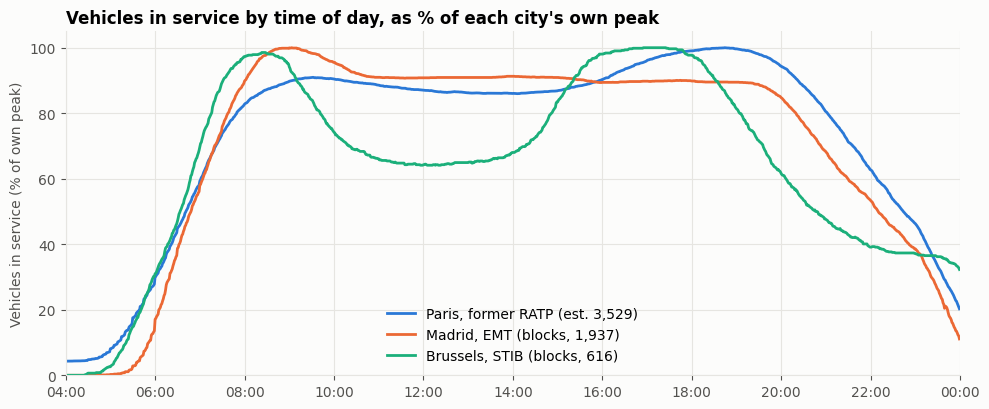

peak_vehicles (E)       3529
peak_time              18:44
vehicles_08:00          2921
vehicles_12:00          3071
vehicles_17:00          3392
midday_as_%_of_peak     87.0
duties                  4772
median_duty_h           14.2


In [10]:
# Vehicles in service by time of day, indexed to each city's own peak (one common axis)
bxl_min = pd.read_csv("../Brussels/outputs/vehicles_in_service_by_minute.csv")
hours = np.arange(24 * 60) / 60
fig, ax = plt.subplots(figsize=(10, 4.2))
series = [(par_curve[:1440], f"Paris, former RATP (est. {PAR_PEAK:,})", C1),
          (mad_curve_b[:1440], f"Madrid, EMT (blocks, {int(mad_curve_b.max()):,})", C2),
          (bxl_min.brussels.values, f"Brussels, STIB (blocks, {bxl_min.brussels.max():,})", C3)]
for curve, name, col in series:
    pct = 100 * curve / curve.max()
    ax.plot(hours, pct, color=col, lw=2, label=name)
ax.set_xlim(4, 24); ax.set_ylim(0, 105)
ax.set_xticks(range(4, 25, 2)); ax.set_xticklabels([f"{h % 24:02d}:00" for h in range(4, 25, 2)])
ax.set_ylabel("Vehicles in service (% of own peak)")
ax.set_title("Vehicles in service by time of day, as % of each city's own peak")
ax.legend(loc="lower center", ncol=1)
fig.tight_layout(); fig.savefig(f"{OUT}/fig_paris_vehicles_by_hour.png", dpi=160); plt.show()

prof = {"peak_vehicles (E)": PAR_PEAK, "peak_time": f"{pk // 60:02d}:{pk % 60:02d}",
        "vehicles_08:00": int(par_curve[8 * 60]), "vehicles_12:00": int(par_curve[12 * 60]),
        "vehicles_17:00": int(par_curve[17 * 60]),
        "midday_as_%_of_peak": round(100 * par_curve[12 * 60] / PAR_PEAK, 1),
        "duties": len(par_blk), "median_duty_h": round(par_blk.hours.median(), 1)}
print(pd.Series(prof).to_string())
pd.DataFrame({"minute": np.arange(1440), "paris_est": par_curve[:1440].astype(int)}) \
  .to_csv(f"{OUT}/paris_vehicles_in_service_by_minute.csv", index=False)

## 5. Energy and charging

**File 1 energy (brief, mandatory):** `energy_full_bev_mwh_day = daily_bus_km x 1.30 / 1000`, the same factor for every city. It is battery energy before charging losses, and it assumes nothing about Paris's real bus mix.

**Indicative charging check (E):** per line, km per bus per day = line km / estimated peak buses on the line, compared with the brief's effective daily range (300 km for a 12 m bus). Paris's line-level articulated-bus mix is not published in the sources found, so **all lines are treated as standard 12 m buses**. This is a screening only: the brief does not require line-level plans for comparison cities.

**Grid power at the depots (C):** if all the energy were charged overnight (7 h, 90% efficiency), the average power needed across the network.

In [11]:
PAR_MWH = PAR_KM * BENCH_KWH_KM / 1000
line_peak = par_blk.groupby("line").apply(lambda b: int(_curve(b.start.values, b.end.values).max()), include_groups=False)
e = par.join(line_peak.rename("vehicles_est"))
e["km_per_bus_day"] = (e.daily_km / e.vehicles_est).round(1)
e["energy_kwh_bus_day"] = (e.km_per_bus_day * BENCH_KWH_KM).round(1)
e["screen"] = np.where(e.km_per_bus_day > RANGE_KM["Standard"], "Above 300 km: opportunity charging", "Depot only")
grid_mwh = PAR_MWH / CHARGE_EFF
night_mw = grid_mwh / NIGHT_HOURS
print(f"Full-BEV battery energy (C, brief formula): {PAR_KM:,.0f} km x {BENCH_KWH_KM} kWh/km = {PAR_MWH:,.1f} MWh/day")
print(f"Grid energy at 90% efficiency: {grid_mwh:,.1f} MWh/day | managed overnight power over 7 h: {night_mw:,.1f} MW (whole network)")
print(f"Annual, 365 equivalent days (brief annualisation): {PAR_MWH * 365 / 1000:,.1f} GWh battery energy")
print(f"\nkm per bus per day (E): median {e.km_per_bus_day.median():.0f} km | max {e.km_per_bus_day.max():.0f} km (line {e.km_per_bus_day.idxmax()})")
print(e.screen.value_counts().to_string())
print("\nLines above the 300 km daily range (E):")
print(e[e.km_per_bus_day > RANGE_KM["Standard"]][["agency_name", "daily_km", "vehicles_est", "km_per_bus_day"]].to_string())
e.to_csv(f"{OUT}/paris_energy_model.csv")

Full-BEV battery energy (C, brief formula): 510,433 km x 1.3 kWh/km = 663.6 MWh/day
Grid energy at 90% efficiency: 737.3 MWh/day | managed overnight power over 7 h: 105.3 MW (whole network)
Annual, 365 equivalent days (brief annualisation): 242.2 GWh battery energy

km per bus per day (E): median 130 km | max 328 km (line 350)
screen
Depot only                            289
Above 300 km: opportunity charging      1

Lines above the 300 km daily range (E):
         agency_name  daily_km  vehicles_est  km_per_bus_day
line                                                        
350   Express Roissy    3610.9            11           328.3


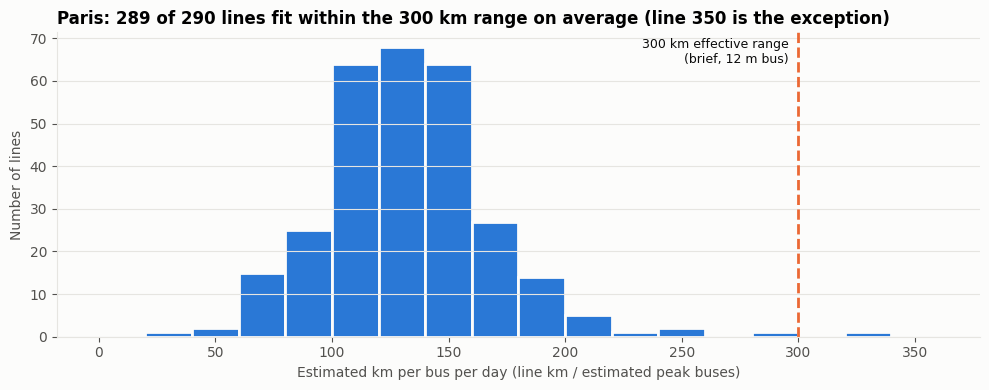

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(e.km_per_bus_day, bins=np.arange(0, 361, 20), color=C1, edgecolor="#fcfcfb", linewidth=2)
ax.axvline(RANGE_KM["Standard"], color=C2, lw=2, ls="--")
ax.text(RANGE_KM["Standard"] - 4, ax.get_ylim()[1] * 0.9, "300 km effective range\n(brief, 12 m bus)", ha="right", color=INK, fontsize=9)
ax.set_xlabel("Estimated km per bus per day (line km / estimated peak buses)")
ax.set_ylabel("Number of lines"); ax.grid(axis="x", visible=False)
n_ok = int((e.km_per_bus_day <= RANGE_KM["Standard"]).sum())
ax.set_title(f"Paris: {n_ok} of {len(e)} lines fit within the 300 km range on average (line 350 is the exception)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_paris_km_per_bus.png", dpi=160); plt.show()

## 6. Fleet, zero-emission share and targets (sourced)

All values in this section come from published sources **(S)**. None are computed from the timetable.

| Item | Value | Date it refers to | Source |
|---|---|---|---|
| RATP bus fleet in Île-de-France | about 1,100 electric, 1,300 biomethane, 1,100 hybrid, 1,100 diesel (3,500 "clean" + 1,100 diesel) | "Début 2026" | ratp.fr, Bus2025 page |
| Hydrogen buses | 22, operated by RATP at Créteil (line 103) | 2025-2026 | ratp.fr, Bus2025 page; transbus.org: 22 Solaris Urbino 12 Hydrogen registered by IDFM in 2025 |
| RATP EPIC + RATP Cap IdF buses | 5,407 total; fleet mix 21% hybrid, 21% electric, 27% NGV | End 2025 | RATP Group 2025 activity and sustainability report (p. 8) |
| Historic RATP fleet in Bus2025 | 4,600 buses | Programme scope | same report (p. 24) |
| Clean buses | 75% (electric, biomethane, hybrid) | End 2025 | RATP Group annual results 2025 (13 Mar 2026) |
| IDFM target | 100% "clean" buses: dense area 2025, whole region 2029; energy mix target 70% biomethane / 30% electric; no diesel by end 2025 | Current | IDFM, "mobilité décarbonée" page |
| RATP Group target | "operating exclusively low-carbon buses in Île-de-France by 2029" | Current | RATP Group 2025 report (p. 17) |

**Choices for File 1:**
- **`fleet_total` = 4,622 (E, documented proxy)** = 4,600 (sum of RATP's four rounded categories, "début 2026") + 22 hydrogen buses, which RATP lists separately on the same page. It is the closest published date to 31 Dec 2025 for the historic RATP network. The figures are rounded to the nearest hundred, so the precision is roughly ±100 buses.
- **`ze_fleet` = 1,122 (E)** = about 1,100 battery-electric + 22 hydrogen. Biomethane and hybrid buses are **not** zero-emission and are excluded, as the brief requires.
- **Cross-check:** 21% electric x 5,407 (RATP EPIC + RATP Cap at end 2025) = 1,135 electric buses. That is close to 1,100, but the 5,407 scope also includes RATP Cap networks outside the perimeter (for example Saclay, Bièvre, Mantois), so it is not used for `fleet_total`.
- **`ze_target_year` = empty.** IDFM's and RATP's commitments are to **"clean"/"low-carbon"** buses, where 70% of the target mix is biomethane. No commitment to a 100% zero-tailpipe fleet was found. The brief says such clean-only targets must not be used.
- **`charging_model` = Depot.** RATP's reference model is overnight charging in bus depots (IDFM/RATP Bus2025 dossier, Oct 2020; RATP–Enedis partnership, 2018), with smart charging rolled out in 6 depots covering 745 buses and 605 charging points by end 2025 (RATP 2025 report, p. 24). No terminus (opportunity) charging on this network was found in the sources.

fleet_total (E): 4,622 | ze_fleet (E): 1,122 | ze_share: 24.3%
Clean share (electric + biomethane + hybrid + hydrogen): 76.2% (RATP reports 75% at end 2025)
Cross-check: 21% x 5,407 = 1,135 electric buses (RATP EPIC + RATP Cap, wider scope)
Spare ratio: fleet 4,622 / estimated peak in service 3,529 = 1.31


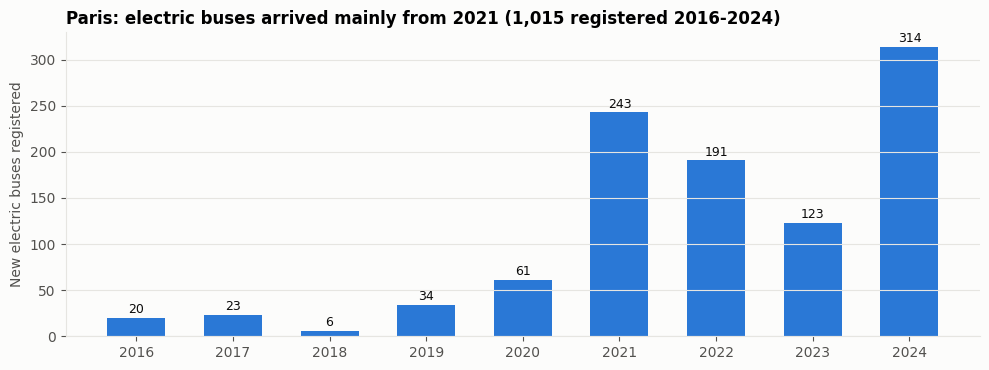

In [13]:
FLEET = {"electric_bev": 1100, "biomethane": 1300, "hybrid": 1100, "diesel": 1100, "hydrogen": 22}   # (S) ratp.fr, début 2026
PAR_FLEET_TOTAL = sum(FLEET.values())                 # (E) 4,622
PAR_ZE = FLEET["electric_bev"] + FLEET["hydrogen"]    # (E) 1,122
PAR_ZE_SHARE = round(100 * PAR_ZE / PAR_FLEET_TOTAL, 1)
print(f"fleet_total (E): {PAR_FLEET_TOTAL:,} | ze_fleet (E): {PAR_ZE:,} | ze_share: {PAR_ZE_SHARE}%")
print(f"Clean share (electric + biomethane + hybrid + hydrogen): "
      f"{100 * (PAR_FLEET_TOTAL - FLEET['diesel']) / PAR_FLEET_TOTAL:.1f}% (RATP reports 75% at end 2025)")
print(f"Cross-check: 21% x 5,407 = {0.21 * 5407:,.0f} electric buses (RATP EPIC + RATP Cap, wider scope)")
print(f"Spare ratio: fleet {PAR_FLEET_TOTAL:,} / estimated peak in service {PAR_PEAK:,} = {PAR_FLEET_TOTAL / PAR_PEAK:.2f}")

# Electric bus registrations on the RATP perimeter, 2016-2024 (S): transbus.org, Feb 2025
reg = pd.Series({2016: 20, 2017: 23, 2018: 6, 2019: 34, 2020: 61, 2021: 243, 2022: 191, 2023: 123, 2024: 314})
assert reg.sum() == 1015   # total published by the source
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(reg.index, reg.values, color=C1, width=0.6)
for x_, v in reg.items():
    ax.text(x_, v + 5, f"{v}", ha="center", fontsize=9, color=INK)
ax.set_xticks(reg.index); ax.grid(axis="x", visible=False)
ax.set_ylabel("New electric buses registered")
ax.set_title("Paris: electric buses arrived mainly from 2021 (1,015 registered 2016-2024)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_paris_ebus_registrations.png", dpi=160); plt.show()
pd.DataFrame([FLEET]).assign(date="début 2026", source="ratp.fr Bus2025 page").to_csv(f"{OUT}/paris_fleet_mix.csv", index=False)

## 7. Depots and grid power

**Depots (S):** Bus2025 converted RATP's **25 bus depots** ("centres bus"): **13 to 100% electric** (Lagny, Corentin, Pleyel, Lilas, Belliard, Lebrun, Croix-Nivert, Malakoff, Point-du-Jour, Asnières, Charlebourg, Vitry, Neuilly Bords de Marne) and **12 to biomethane** (Créteil, Bussy, Massy, Nanterre, Thiais, Aubervilliers, Pavillons, Flandre, Ivry, Saint-Denis, Saint-Maur, Fontenay-aux-Roses) (ratp.fr, Bus2025 page). At end 2025, RATP reported **10 depots converted to electric and 12 to biomethane** (RATP 2025 report, p. 17). Bussy is now outside the perimeter (Keolis since Nov 2025).

**Which lot runs which depot (S, transbus.org and RATP press releases):**

| Lot | Depots |
|---|---|
| 48 Rive Gauche | Croix-Nivert, Lebrun, Malakoff, Montrouge/Corentin (the sources name it differently) |
| 49 Rive Droite | Belliard, Lagny, Les Lilas (RATP's release also lists Gallieni) |
| 41 Défense - Saint-Cloud | Point-du-Jour, Charlebourg, two Nanterre sites |
| 43 Plaine Saint-Denis | Aubervilliers, Saint-Denis, Villiers-le-Bel |
| 44 Ourcq | Flandre, Pavillons |
| 42 Boucles Nord de Seine | Asnières, Pleyel |
| 45 Bords de Marne | Bord de Marne (Neuilly-Plaisance), Saint-Maur |
| 46 Pompadour | Thiais, Créteil |
| 47 Seine Orly | Ivry, Vitry (plus Villeneuve-le-Roi, ex-Keolis) |
| 36 Massy-Juvisy | Massy (plus Morangis, ex-Keolis) |
| 40 Croix du Sud | not stated in the sources found |

**Grid connection (S):** RATP's own engineering study found that charging needs a connection **"de l'ordre de 10 à 15 MW par centre bus"**, depending on the number of buses (Annales des Mines, *Enjeux numériques*, Sept 2021, RATP authors). Point-du-Jour was connected at high voltage by Enedis and has 90 bus chargers (RATP press release, 5 Feb 2025). RATP's model is to charge at night, off-peak, so as not to saturate the grid (RATP–Enedis partnership, March 2018).

**What this means (C):** the check below compares the whole network's overnight need, if fully electric, with that published per-depot range. It is a network total, not a per-depot model: Paris's line-to-depot allocation is not published in the feed.

In [14]:
N_ELEC_DEPOTS = 13
lo, hi = 10 * N_ELEC_DEPOTS, 15 * N_ELEC_DEPOTS
print(f"Network overnight need if 100% BEV (C): {night_mw:,.0f} MW (managed, 7 h, 90% efficiency)")
print(f"13 electric depots x 10-15 MW (S, RATP study range): {lo}-{hi} MW")
print(f"=> about {night_mw / N_ELEC_DEPOTS:.1f} MW per electric depot if all energy went to the 13 electric depots;"
      f" the remaining depots are biomethane by design, so Paris does not need a 100% electric grid connection")
print(f"Electric fleet only (1,100 BEV x {e.km_per_bus_day.median():.0f} km median x 1.30 kWh/km / 0.9 / 7 h): "
      f"{1100 * e.km_per_bus_day.median() * BENCH_KWH_KM / CHARGE_EFF / NIGHT_HOURS / 1000:,.1f} MW (E)")

Network overnight need if 100% BEV (C): 105 MW (managed, 7 h, 90% efficiency)
13 electric depots x 10-15 MW (S, RATP study range): 130-195 MW
=> about 8.1 MW per electric depot if all energy went to the 13 electric depots; the remaining depots are biomethane by design, so Paris does not need a 100% electric grid connection
Electric fleet only (1,100 BEV x 130 km median x 1.30 kWh/km / 0.9 / 7 h): 29.5 MW (E)


## 8. Emissions

**What can be stated from sources (S):**
- Bus2025 cut the CO2 from bus operations by **50% between 2015 and 2025**, about **250,000 tCO2 avoided** over the period (ratp.fr Bus2025 page; RATP Group "soft mobility" page).
- RATP Group: -40% GHG from RATP energy use vs 2019 (-152,211 tCO2e), against a target of -43% by 2027 (RATP annual results 2025). This covers all RATP energy use, not buses alone.
- French electricity generation: **19.6 gCO2e/kWh** in 2025 (direct emissions; 29.0 g life-cycle) (RTE, Bilan électrique 2025).

**Gap:** an absolute 2025 tonnage for the bus network alone was **not found** in the published sources. It is not estimated here, because doing so would need fuel-consumption factors for Paris's diesel, hybrid and biomethane buses that are not published.

**What the brief's method gives (C):** the electricity CO2 of a fully battery-electric Paris network, at the brief's 1.30 kWh/km and France's 2025 grid factor.

In [15]:
GRID_CO2_FR = 19.6   # gCO2e/kWh, RTE Bilan électrique 2025, direct emissions of generation (S)
annual_grid_mwh = PAR_MWH / CHARGE_EFF * 365
co2_full_bev_t = annual_grid_mwh * GRID_CO2_FR / 1000
print(f"Full-BEV electricity: {annual_grid_mwh / 1000:,.1f} GWh/year (grid side, 365 days)")
print(f"x {GRID_CO2_FR} gCO2e/kWh = {co2_full_bev_t:,.0f} tCO2e/year (C)")
print(f"Per bus-km: {BENCH_KWH_KM / CHARGE_EFF * GRID_CO2_FR:.1f} gCO2e/km in Paris "
      f"vs {BENCH_KWH_KM / CHARGE_EFF * 108.4:.1f} gCO2e/km at Madrid's fixed Spanish factor (0.1084 kg/kWh, Madrid notebook)")

Full-BEV electricity: 269.1 GWh/year (grid side, 365 days)
x 19.6 gCO2e/kWh = 5,275 tCO2e/year (C)
Per bus-km: 28.3 gCO2e/km in Paris vs 156.6 gCO2e/km at Madrid's fixed Spanish factor (0.1084 kg/kWh, Madrid notebook)


## 9. Benchmark table and the File 1 row

Madrid values are taken from the Madrid outputs (`File_2.csv` for lines and km, `File_4.csv` 2026 S0 row for the 31 Dec 2025 fleet baseline, as the brief requires). Brussels values are taken from the Brussels notebook's output. Each city keeps its own reference day.

In [16]:
f2 = pd.read_csv(MADRID_FILE2); f4 = pd.read_csv(MADRID_FILE4)
bx = pd.read_csv(BXL_BENCH, index_col=0)
MAD_LINES, MAD_KM = len(f2), f2.daily_km.sum()
MAD_FLEET, MAD_ZE = 2210, 452 + 10        # Madrid notebook baseline at 31 Dec 2025 (BEV 452 + H2 10)
bench = pd.DataFrame({
    "Madrid (EMT)": [MAD_LINES, MAD_KM, int(mad_curve_b.max()), MAD_FLEET, MAD_ZE, round(100 * MAD_ZE / MAD_FLEET, 1),
                     MAD_KM * BENCH_KWH_KM / 1000, MAD_KM / mad_curve_b.max()],
    "Paris (ex-RATP)": [PAR_LINES, PAR_KM, PAR_PEAK, PAR_FLEET_TOTAL, PAR_ZE, PAR_ZE_SHARE, PAR_MWH, PAR_KM / PAR_PEAK],
    "Brussels (STIB)": [bx.loc["Bus lines (weekday)", "Brussels (STIB)"], bx.loc["Daily bus-km", "Brussels (STIB)"],
                        bx.loc["Peak vehicles in service (GTFS blocks)", "Brussels (STIB)"], np.nan, np.nan, np.nan,
                        bx.loc["Daily bus-km", "Brussels (STIB)"] * BENCH_KWH_KM / 1000,
                        bx.loc["km per peak vehicle per day (blocks)", "Brussels (STIB)"]],
}, index=["Bus lines (reference day)", "Daily bus-km", "Peak vehicles in service", "Fleet (end 2025)",
          "Zero-emission buses", "Zero-emission share %", "Full-BEV energy at 1.30 kWh/km (MWh/day)",
          "km per peak vehicle per day"])
bench["Paris / Madrid"] = (bench["Paris (ex-RATP)"] / bench["Madrid (EMT)"]).round(2)
print(bench.round(1).to_string())
print("\nNotes: Paris peak vehicles are estimated (no block_id); Madrid peak from real GTFS blocks; "
      "Brussels fleet is left to the Brussels row of File 1.")
bench.round(2).to_csv(f"{OUT}/benchmark_madrid_vs_paris.csv")

                                          Madrid (EMT)  Paris (ex-RATP)  Brussels (STIB)  Paris / Madrid
Bus lines (reference day)                        234.0            290.0             51.0             1.2
Daily bus-km                                  339219.7         510433.1          91639.0             1.5
Peak vehicles in service                        1937.0           3529.0            616.0             1.8
Fleet (end 2025)                                2210.0           4622.0              NaN             2.1
Zero-emission buses                              462.0           1122.0              NaN             2.4
Zero-emission share %                             20.9             24.3              NaN             1.2
Full-BEV energy at 1.30 kWh/km (MWh/day)         441.0            663.6            119.1             1.5
km per peak vehicle per day                      175.1            144.6            148.8             0.8

Notes: Paris peak vehicles are estimated (no block_id)

In [17]:
SOURCES = ";".join([
    "https://prim.iledefrance-mobilites.fr/en/jeux-de-donnees/offre-horaires-tc-gtfs-idfm",
    "https://ratpgroup.com/fr/realisations/ouverture-concurrence-bus/",
    "https://www.transbus.org/actualite/actu-2026-11-idfm-concurrence-rive-gauche-rive-droite.html",
    "https://www.iledefrance-mobilites.fr/actualites/locales/detail/lancement9517",
    "https://www.groupe-sncf.com/en/group/about-us/companies/keolis/strengthens-positions-paris-inner-suburbs",
    "https://www.ratp.fr/groupe-ratp/programmebus2025",
    "https://ratpgroup.com/api/media/radd-2025-uk.pdf",
    "https://www.iledefrance-mobilites.fr/dossiers/ile-de-france-mobilites-une-mobilite-decarbonee",
    "https://analysesetdonnees.rte-france.com/en/annual-review-2025/ghg-emissions",
])
FILE1_COLS = ["city", "operator", "reference_date", "n_bus_lines", "daily_bus_km", "fleet_total", "ze_fleet",
              "ze_share_pct", "fleet_data_year", "ze_target_year", "charging_model", "energy_full_bev_mwh_day",
              "grid_co2_g_kwh", "source_urls"]
paris_row = pd.DataFrame([{
    "city": "Paris",
    "operator": "Île-de-France Mobilités (former RATP bus network: DSP lots 36, 40-49 and lines 350/351)",
    "reference_date": ref_ts.strftime("%Y-%m-%d"),
    "n_bus_lines": int(PAR_LINES),
    "daily_bus_km": round(float(PAR_KM), 1),
    "fleet_total": int(PAR_FLEET_TOTAL),
    "ze_fleet": int(PAR_ZE),
    "ze_share_pct": PAR_ZE_SHARE,
    "fleet_data_year": 2025,
    "ze_target_year": pd.NA,               # only 'clean' targets exist (IDFM 2029, 70% biomethane): left empty per brief
    "charging_model": "Depot",
    "energy_full_bev_mwh_day": round(float(PAR_MWH), 1),
    "grid_co2_g_kwh": GRID_CO2_FR,
    "source_urls": SOURCES,
}])[FILE1_COLS]
paris_row = paris_row.astype({"ze_target_year": "Int64"})
paris_row.to_csv(f"{OUT}/File_1_paris_row.csv", index=False, encoding="utf-8")

back = pd.read_csv(f"{OUT}/File_1_paris_row.csv")
print("File_1_paris_row.csv as saved:")
print(back.dtypes.to_string()); print("rows:", len(back))
show = back.T.copy(); show.iloc[-1, 0] = str(show.iloc[-1, 0])[:90] + " ... (" + str(back.source_urls[0].count(";") + 1) + " URLs)"
print(show.to_string())
print("\nsource_urls:"); print("\n".join(back.source_urls[0].split(";")))
assert list(back.columns) == FILE1_COLS
assert abs(back.ze_share_pct[0] - round(100 * back.ze_fleet[0] / back.fleet_total[0], 1)) < 1e-9
assert abs(back.energy_full_bev_mwh_day[0] - round(back.daily_bus_km[0] * 1.30 / 1000, 1)) < 0.05
assert back.ze_target_year.isna().all()
print("\nPASS: columns, ze_share_pct and energy formula match the brief; ze_target_year empty (clean-only targets)")

File_1_paris_row.csv as saved:
city                        object
operator                    object
reference_date              object
n_bus_lines                  int64
daily_bus_km               float64
fleet_total                  int64
ze_fleet                     int64
ze_share_pct               float64
fleet_data_year              int64
ze_target_year             float64
charging_model              object
energy_full_bev_mwh_day    float64
grid_co2_g_kwh             float64
source_urls                 object
rows: 1
                                                                                                                               0
city                                                                                                                       Paris
operator                                 Île-de-France Mobilités (former RATP bus network: DSP lots 36, 40-49 and lines 350/351)
reference_date                                                                      

## 10. Sources, assumptions register and gaps

**Assumptions and proxies** (S = sourced, C = computed here, E = estimate):

| ID | Item | Value | Type | Basis |
|---|---|---|---|---|
| P01 | Perimeter | 11 DSP lots + lines 350/351, minus 5 ex-Optile Seine Orly routes | S + E | Lot list and dates: RATP Group, transbus.org, IDFM. The 5 excluded routes are identified by IDFM line code series (E); the count of 5 is sourced (Keolis) |
| P02 | Lots 42 and 45 (RATP Cap since 1 Nov 2025) | included | E | "RATP" read as RATP Group; strict EPIC-only variant shown in Section 3 |
| P03 | Bussy-Saint-Martin depot lines (Keolis since 1 Nov 2025) | excluded | S | transbus.org, Nov 2025 |
| P04 | RoissyBus (352) | not measurable | S | Discontinued 28 Feb 2026 (transbus.org; IDFM) |
| P05 | Reference day | Tue 24 Nov 2026 | C + S | Feed validity; zone C calendar; no strike found as of 19 Nov 2026 (re-check) |
| P06 | Trip length | shape length; stop distance x median ratio where the shape is over 1.5x stop distance | C + E | Section 3 |
| P07 | Vehicles in service | greedy chaining, 2 min layover, 60 min max idle | E | No `block_id` in IDFM feed; method validated on Madrid (Section 4) |
| P08 | fleet_total | 4,622 | E | ratp.fr "début 2026" rounded categories + 22 H2 |
| P09 | ze_fleet | 1,122 | E | ~1,100 BEV + 22 H2 |
| P10 | fleet_data_year | 2025 | E | Source dated "début 2026", the closest to 31 Dec 2025 |
| P11 | ze_target_year | empty | S | Only "clean" targets (IDFM: 2029; mix 70% biomethane) |
| P12 | charging_model | Depot | S | RATP/IDFM: overnight depot charging; no terminus charging found |
| P13 | grid_co2_g_kwh | 19.6 | S | RTE Bilan électrique 2025, direct emissions of generation |
| P14 | Bus type for charging screen | all standard 12 m | E | Line-level articulated mix not published |

**Gaps to state in the report:**
1. No exact fleet count at 31 Dec 2025 for this exact perimeter; RATP publishes rounded figures ("environ").
2. No absolute 2025 bus CO2 tonnage for the network.
3. No published per-depot grid connection figures, only RATP's 10–15 MW per depot range.
4. Vehicles in service are estimated; real duty schedules are not in the open data.
5. The reference day is in the future at the time of writing (19 Nov 2026); strike news must be re-checked.

**Sources** (all accessed 19 Nov 2026):
- IDFM GTFS Datahub (PRIM): https://prim.iledefrance-mobilites.fr/en/jeux-de-donnees/offre-horaires-tc-gtfs-idfm
- RATP Group, opening of the bus network to competition: https://ratpgroup.com/fr/realisations/ouverture-concurrence-bus/
- RATP Group press release, lots 48 and 49 (17 Oct 2025): https://ratpgroup.com/api/media/251017---cp---le-groupe-ratp-remporte-lexploitation-des-deux-lots-de-bus-parisiens-et-reste-loperateur-majeur-du-reseau-de-bus-de-paris-et-petite-couronne.pdf
- transbus.org, lots 42/45 and Bussy (Nov 2025): https://www.transbus.org/actualite/actu-2025-11-idfm-ratp-ouverture-concurrence-lignes-de-bus.html
- transbus.org, lots 41/43/44 (May 2026): https://www.transbus.org/actualite/actu-2026-05-ile-de-france-poursuite-ouverture-concurrence.html
- transbus.org, lots 46/47 (Aug 2026): https://www.transbus.org/actualite/actu-2026-08-idfm-concurrence-pompadour-seine-orly.html
- transbus.org, lots 48/49 (Nov 2026): https://www.transbus.org/actualite/actu-2026-11-idfm-concurrence-rive-gauche-rive-droite.html
- transbus.org, Croix du Sud: https://www.transbus.org/reseaux/92260.html
- transbus.org, RoissyBus end: https://www.transbus.org/actualite/actu-2026-02-arret-ligne-roissybus-ratp-paris.html
- IDFM, lines 350/351 and 9517: https://www.iledefrance-mobilites.fr/actualites/locales/detail/lancement9517
- Keolis (SNCF Group), Seine-Orly contract: https://www.groupe-sncf.com/en/group/about-us/companies/keolis/strengthens-positions-paris-inner-suburbs
- ratp.fr, Bus2025 programme: https://www.ratp.fr/groupe-ratp/programmebus2025
- RATP Group 2025 activity and sustainability report: https://ratpgroup.com/api/media/radd-2025-uk.pdf
- RATP Group annual results 2025: https://ratpgroup.com/en/media-and-publication/press-releases/ratp-group-annual-results-2025/
- transbus.org, 1,000th RATP electric bus and registrations: https://www.transbus.org/actualite/actu-2025-02-1000-bus-electriques-ratp.html
- transbus.org, hydrogen buses: https://www.transbus.org/actualite/pic_2026_05.html
- IDFM, decarbonised mobility targets: https://www.iledefrance-mobilites.fr/dossiers/ile-de-france-mobilites-une-mobilite-decarbonee
- IDFM/RATP Bus2025 dossier (Oct 2020), depot charging model: https://iledefrance-mobilites.fr/medias/portail-idfm/82709a6f-0dfe-4390-9ce2-6c0b4e47fc40_Transition%20energétique%20des%20bus%20Paris%20et%20petite%20couronne.pdf
- RATP press release, Point-du-Jour (5 Feb 2025): https://ratpgroup.com/api/media/20250205-CP-CB-Point-du-Jour-1000e-bus-electrique-1.pdf
- Annales des Mines, RATP depot connection study (Sept 2021): https://annales.org/edit/enjeux-numeriques/2021/en-2021-09/2021-09-12.pdf
- RTE, Bilan électrique 2025, emissions: https://analysesetdonnees.rte-france.com/en/annual-review-2025/ghg-emissions
- School calendar 2026-2027 (zone C): https://www.service-public.gouv.fr/particuliers/actualites/A18563
- French National Assembly report on the RATP bus opening (315 lines, 4,800 buses, 2023): https://questions.assemblee-nationale.fr/dyn/16/rapports/cion-dvp/l16b1838_rapport-fond.pdf

## 11. Key findings and lessons for Madrid (analysis, not data)

*This section interprets the numbers above. It is our analysis, kept separate from the sourced and computed facts.*

1. **Scale.** Paris's former RATP network is the largest peer: 290 lines vs Madrid's 234 (1.2x), about 510,000 bus-km per weekday (1.5x), an estimated 3,529 buses in service at peak (1.8x) and a fleet of about 4,600 (2.1x).
2. **Similar zero-emission share, different strategy.** About 24% of the Paris fleet is zero-emission (Madrid: 21%). But Paris also runs about 1,300 biomethane and 1,100 hybrid buses, and its official targets are "clean" (70% biomethane / 30% electric by 2029), not zero-emission, so File 1 has no target year for Paris. Lesson: biomethane can be a bridge for Madrid's CNG buses, but it does not count as zero-tailpipe under the brief, and the roadmap should say so.
3. **Depot conversion is the real bottleneck, and Paris did it depot by depot.** RATP converted 25 depots, up to 15 at the same time, half to electric and half to biomethane, and RATP's own study sized each electric depot at about 10–15 MW. Madrid's model needs 10–17 MW of managed charging power per depot (`File_3`), the same order of magnitude, which makes Madrid's depot estimates plausible.
4. **Managed (smart) charging is proven at scale.** By end 2025, RATP ran smart charging in 6 depots for 745 buses and 605 charging points and reports 10% lower charging costs. This supports Madrid planning on managed rather than unmanaged peak power.
5. **Daily profile and range.** Paris keeps about 87% of its peak buses in service at midday, close to Madrid (91%) and unlike Brussels (64%), so there is little midday idle time for charging in either city. Even so, a Paris bus covers about 145 km per day on average against Madrid's 175 km, and only one Paris line (350, the airport line) exceeds the 300 km range in the screen. Madrid's longer daily distance per bus makes its charging problem tighter than Paris's.
6. **Limits of the comparison.** Paris is in the middle of a change of operators (12 lots between Nov 2025 and Nov 2026), RATP's fleet figures are rounded, and Paris vehicles are estimated (the method is within 3.5% of Madrid's real blocks). Grid carbon intensity differs a lot (France 19.6 g/kWh vs Spain 108 g/kWh in the Madrid model), so the CO2 saved per electric km is about 5 times lower in Paris and does not transfer one to one.